# Citizen Science Profile

Visualizes the standardized profile of a citizen science project. Run the cells top to bottom: the first sets the color theme, every cell after that draws one chart.

In [10]:
# Theme: pick the color family used by all charts (pumpkin, apricot, apple, teal, blueberry, eggplant, dragonfruit)
COLOR_FAMILY = "teal"
PALETTE_FILE = "colorpalette.json"  # path to the palette file, relative to the notebook

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

with open(Path(PALETTE_FILE)) as f:
    _data = json.load(f)
palette = _data["palettes"]
type_colors = _data["assignments"]["Project type (Wiggins and Crowston)"]["colors"]

families = palette["Color families"]
neutrals = palette["Neutrals"]


def shade(name, family=None):
    """Hex of one shade (lighter, light, base, dark, darker) of a color family."""
    family = family or COLOR_FAMILY
    return families["families"][family][families["shades"].index(name)]


def neutral(role):
    """Hex of a neutral role (background, gridline, axis, text, ...) via the grey ramp."""
    return neutrals["ramp"][neutrals["roles"][role]]


plt.rcParams["font.family"] = "sans-serif"
print(f"Theme: {COLOR_FAMILY}", {s: shade(s) for s in families["shades"]})

Theme: teal {'lighter': '#DDF2EF', 'light': '#98D9D1', 'base': '#56B9B9', 'dark': '#236F7B', 'darker': '#0D2732'}


## Project type

Wiggins and Crowston [16]: five project types: *action*, *conservation*, *investigation*, *virtual* and *education*.

Input is one value from 0 to 100 per type, drawn as a circular bar chart. Each type has a fixed color from the palette file, and every type keeps its slot (a faint track) even when its value is 0. Every color can be overridden.

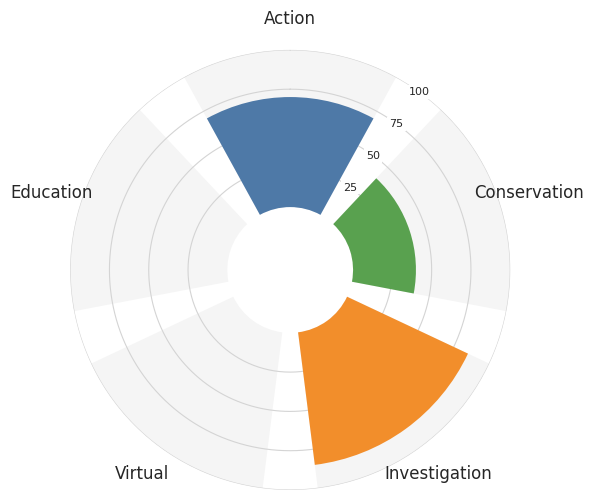

In [11]:
PROJECT_TYPES = ["action", "conservation", "investigation", "virtual", "education"]


def plot_project_type_chart(
    values,
    colors=None,          # {type: hex}; default: fixed project type colors from the palette file
    background="white",
    track_color=None,     # full-length slot behind each bar; default: lightest grey
    ring_color=None,      # circles at 25/50/75/100; default: light grey
    text_color=None,      # labels; default: neutral text
    hole=40,              # empty center, in value units
    figsize=(6, 6),
    save_to=None,
):
    """Circular bar chart of the five Wiggins and Crowston project types.

    values: dict {type: 0-100} with all five types.
    """
    missing = [t for t in PROJECT_TYPES if t not in values]
    extra = [t for t in values if t not in PROJECT_TYPES]
    if missing or extra:
        raise ValueError(f"Expected exactly {PROJECT_TYPES}; missing {missing}, unexpected {extra}")
    if not all(0 <= values[t] <= 100 for t in PROJECT_TYPES):
        raise ValueError("All values must be between 0 and 100")

    colors = {**type_colors, **(colors or {})}
    ramp = palette["Neutrals"]["ramp"]
    track_color = track_color or ramp["grey-100"]
    ring_color = ring_color or ramp["grey-300"]
    text_color = text_color or neutral("text")

    n = len(PROJECT_TYPES)
    slot = 2 * np.pi / n
    width = slot * 0.8  # leaves a gap between bars
    angles = np.arange(n) * slot

    fig, ax = plt.subplots(figsize=figsize, subplot_kw={"projection": "polar"})
    fig.patch.set_facecolor(background)
    ax.set_facecolor(background)
    ax.set_theta_offset(np.pi / 2)  # first type at the top
    ax.set_theta_direction(-1)      # clockwise
    ax.set_ylim(0, hole + 100)

    ax.grid(False)
    ax.spines["polar"].set_visible(False)
    ax.set_yticks([])

    # tracks keep every type visible, also at 0
    ax.bar(angles, [100] * n, width=width, bottom=hole, color=track_color, linewidth=0, zorder=0)

    # rings with labels sitting on the line, in the gap between two bars
    theta = np.linspace(0, 2 * np.pi, 361)
    label_angle = angles[0] + slot / 2
    for r in (25, 50, 75, 100):
        ax.plot(theta, [hole + r] * len(theta), color=ring_color, linewidth=0.8, zorder=1)
        ax.text(label_angle, hole + r, str(r), ha="center", va="center", fontsize=8, color=text_color,
                bbox=dict(facecolor=background, edgecolor="none", pad=1.5), zorder=4)

    ax.bar(angles, [values[t] for t in PROJECT_TYPES], width=width, bottom=hole,
           color=[colors[t] for t in PROJECT_TYPES], linewidth=0, zorder=2)

    ax.set_xticks(angles)
    ax.set_xticklabels([t.capitalize() for t in PROJECT_TYPES], color=text_color, fontsize=12)
    ax.tick_params(axis="x", pad=12)

    fig.tight_layout()
    if save_to:
        fig.savefig(save_to, dpi=200, facecolor=fig.get_facecolor(), bbox_inches="tight")
    return fig, ax


# Example input: 0-100 per type
project_types = {
    "action": 70,
    "conservation": 40,
    "investigation": 85,
    "virtual": 0,
    "education": 0,
}

fig, ax = plot_project_type_chart(project_types)
plt.show()

## Environmental monitoring campaigns

After Pocock, Tweddle, Savage, et al. [ref]. Only for environmental monitoring campaigns.

The project is placed on two axes: **simple approach → elaborate approach** (vertical) and **systematic monitoring → mass participation** (horizontal). Input is one value from 0 to 100 for each axis: `x` runs from systematic monitoring (0) to mass participation (100), `y` from simple approach (0) to elaborate approach (100).

The grey points in the background mimic the distribution of the papers analysed by Pocock, Tweddle, Savage et al., so you can see where your project sits relative to them. Their positions are in `data/pocock_background_points.csv`; only the points marked `no` in its `computer based` column are drawn. By default the project is drawn in the theme color. Every color can be overridden.

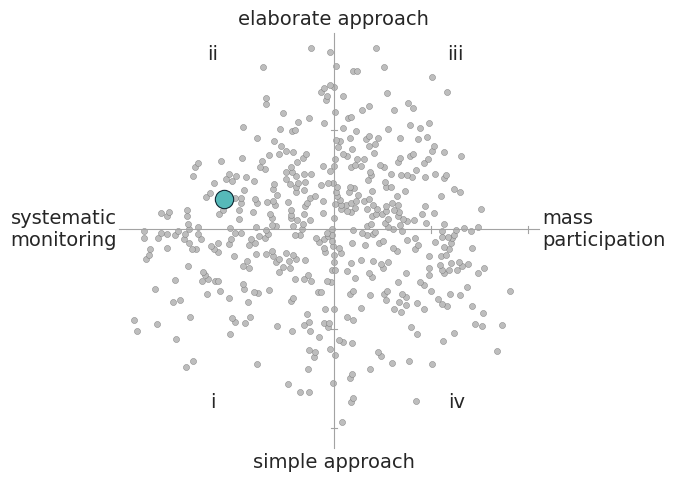

In [13]:
import csv

with open("data/pocock_background_points.csv") as f:
    pocock_points = np.array([[float(r["x"]), float(r["y"])]
                              for r in csv.DictReader(f) if r["computer based"] == "no"])

# plot extent in the units of the background points
POCOCK_XLIM = (-4.50, 4.29)
POCOCK_YLIM = (-4.58, 4.11)


def plot_pocock_chart(
    x,
    y,
    background="white",
    point_color=None,      # background points; default: grey
    point_edge=None,
    highlight_color=None,  # your project; default: theme "base"
    highlight_edge=None,   # default: theme "darker"
    axis_color=None,       # default: grey
    text_color=None,       # default: neutral text
    figsize=(7, 7),
    save_to=None,
):
    """Place a project on Pocock et al.'s two axes.

    x: 0 (systematic monitoring) to 100 (mass participation)
    y: 0 (simple approach) to 100 (elaborate approach)
    """
    if not (0 <= x <= 100 and 0 <= y <= 100):
        raise ValueError("x and y must be between 0 and 100")

    ramp = palette["Neutrals"]["ramp"]
    point_color = point_color or ramp["grey-400"]
    point_edge = point_edge or ramp["grey-600"]
    highlight_color = highlight_color or shade("base")
    highlight_edge = highlight_edge or shade("darker")
    axis_color = axis_color or ramp["grey-500"]
    text_color = text_color or neutral("text")

    (x0, x1), (y0, y1) = POCOCK_XLIM, POCOCK_YLIM
    px = x0 + x / 100 * (x1 - x0)
    py = y0 + y / 100 * (y1 - y0)

    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor(background)
    ax.set_facecolor(background)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([])
    ax.set_yticks([])

    # axes cross in the middle
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_position("zero")
        ax.spines[side].set_color(axis_color)
        ax.spines[side].set_linewidth(0.8)

    # small tick marks
    for tx in (2.04, 4.06):
        ax.plot([tx, tx], [-0.07, 0.07], color=axis_color, linewidth=0.8)
    for ty in (2.075, -2.075, -4.155):
        ax.plot([-0.07, 0.07], [ty, ty], color=axis_color, linewidth=0.8)

    # axis labels
    label = dict(fontsize=14, color=text_color, annotation_clip=False)
    ax.annotate("elaborate approach", (0, 4.2), ha="center", va="bottom", **label)
    ax.annotate("simple approach", (0, -4.68), ha="center", va="top", **label)
    ax.annotate("systematic\nmonitoring", (-4.55, 0), ha="right", va="center", linespacing=1.2, **label)
    ax.annotate("mass\nparticipation", (4.35, 0), ha="left", va="center", linespacing=1.2, **label)

    # quadrant labels
    for text, (qx, qy) in {"ii": (-2.54, 3.66), "iii": (2.55, 3.66), "i": (-2.54, -3.61),
                           "iv": (2.56, -3.61)}.items():
        ax.text(qx, qy, text, ha="center", va="center", fontsize=14, color=text_color)

    # background: distribution of the analysed papers
    ax.scatter(pocock_points[:, 0], pocock_points[:, 1], s=19, color=point_color,
               edgecolor=point_edge, linewidth=0.3, zorder=2)
    # the project
    ax.scatter([px], [py], s=174, color=highlight_color, edgecolor=highlight_edge,
               linewidth=0.8, zorder=3)

    fig.subplots_adjust(left=0.2, right=0.8, bottom=0.1, top=0.9)
    if save_to:
        fig.savefig(save_to, dpi=200, facecolor=fig.get_facecolor(), bbox_inches="tight")
    return fig, ax


# Example input: 0-100 per axis
fig, ax = plot_pocock_chart(x=25, y=60)
plt.show()